# Scoring client : prédire le risque de défaut de crédit

**Objectif** : construire un modèle qui estime la probabilité qu'un client ne rembourse pas son crédit, puis choisir un seuil de décision adapté au coût des erreurs.

**Données** : *German Credit* (1 000 demandes de crédit, 20 variables), un jeu de données de référence en scoring.

**Plan**
1. Chargement et exploration des données
2. Préparation (valeurs extrêmes, encodage, standardisation)
3. Analyse en composantes principales (PCA)
4. Comparaison de modèles en validation croisée
5. Évaluation sur le jeu de test
6. Choix du seuil de décision selon le coût des erreurs
7. Interprétation du modèle
8. Conclusion et limites

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 1. Chargement et exploration des données

In [2]:
df = pd.read_csv("data/credit_allemand.csv")

# Dans le fichier, credit_risk = 1 signifie "bon payeur" et 0 "mauvais payeur".
# On crée une cible plus lisible : defaut = 1 si le client est un mauvais payeur.
df["defaut"] = 1 - df["credit_risk"]
df = df.drop(columns="credit_risk")

print(df.shape)
df.head()

(1000, 21)


,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,present_residence,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,defaut
0,... < 100 DM,6,critical account/other credits existing,domestic appliances,1169,unknown/no savings account,... >= 7 years,4,male : single,none,4,real estate,67,none,own,2,skilled employee/official,1,yes,yes,0
1,0 <= ... < 200 DM,48,existing credits paid back duly till now,domestic appliances,5951,... < 100 DM,1 <= ... < 4 years,2,female : divorced/separated/married,none,2,real estate,22,none,own,1,skilled employee/official,1,no,yes,1
2,no checking account,12,critical account/other credits existing,retraining,2096,... < 100 DM,4 <= ... < 7 years,2,male : single,none,3,real estate,49,none,own,1,unskilled - resident,2,no,yes,0
3,... < 100 DM,42,existing credits paid back duly till now,radio/television,7882,... < 100 DM,4 <= ... < 7 years,2,male : single,guarantor,4,building society savings agreement/life insurance,45,none,for free,1,skilled employee/official,2,no,yes,0
4,... < 100 DM,24,delay in paying off in the past,car (new),4870,... < 100 DM,1 <= ... < 4 years,3,male : single,none,4,unknown/no property,53,none,for free,2,skilled employee/official,2,no,yes,1


In [3]:
print("Valeurs manquantes :", df.isna().sum().sum())
print("Doublons :", df.duplicated().sum())
df.describe()

Valeurs manquantes : 0
Doublons : 0


,duration,amount,installment_rate,present_residence,age,number_credits,people_liable,defaut
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,3271.258000,2.973000,2.845000,35.546000,1.407000,1.155000,0.300000
std,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086,0.458487
min,4.000000,250.000000,1.000000,1.000000,19.000000,1.000000,1.000000,0.000000
25%,12.000000,1365.500000,2.000000,2.000000,27.000000,1.000000,1.000000,0.000000
50%,18.000000,2319.500000,3.000000,3.000000,33.000000,1.000000,1.000000,0.000000
75%,24.000000,3972.250000,4.000000,4.000000,42.000000,2.000000,1.000000,1.000000
max,72.000000,18424.000000,4.000000,4.000000,75.000000,4.000000,2.000000,1.000000


Taux de défaut : 30.0%


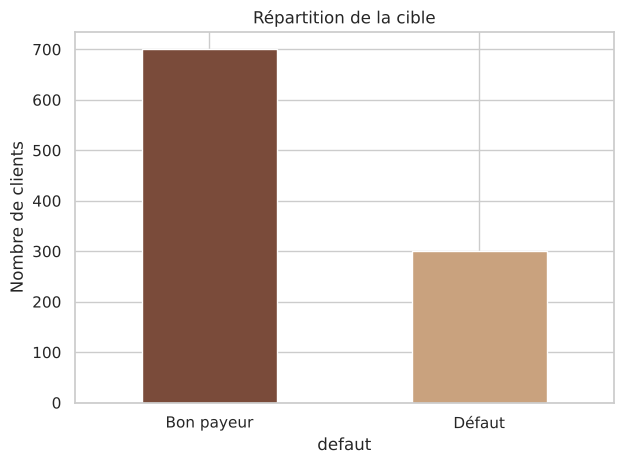

In [4]:
taux = df["defaut"].mean()
print(f"Taux de défaut : {taux:.1%}")

ax = df["defaut"].map({0: "Bon payeur", 1: "Défaut"}).value_counts().plot.bar(color=["#7A4B3A", "#C9A27E"], rot=0)
ax.set_title("Répartition de la cible")
ax.set_ylabel("Nombre de clients")
plt.tight_layout(); plt.savefig("figures/repartition_cible.png", dpi=120); plt.show()

Les classes sont **déséquilibrées** (30 % de défauts). L'accuracy seule serait trompeuse : un modèle qui prédit toujours « bon payeur » obtiendrait déjà 70 %. On suivra donc surtout l'**AUC**, le **rappel** (part des défauts détectés) et la **précision**.

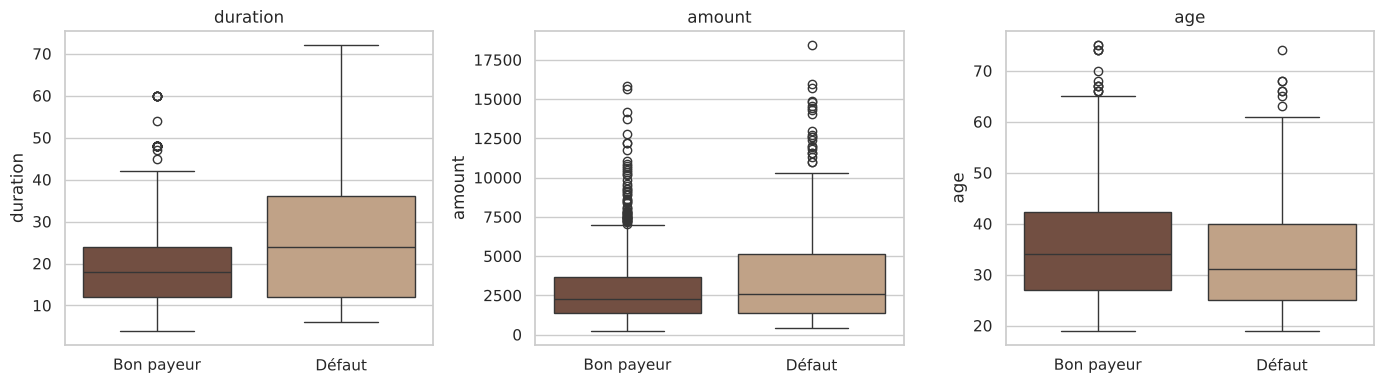

In [5]:
num_cols = ["duration", "amount", "age"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="defaut", y=col, ax=ax, hue="defaut", palette=["#7A4B3A", "#C9A27E"], legend=False)
    ax.set_xticks([0, 1], ["Bon payeur", "Défaut"]); ax.set_xlabel("")
    ax.set_title(col)
plt.tight_layout(); plt.savefig("figures/variables_numeriques.png", dpi=120); plt.show()

Les crédits en défaut sont en moyenne **plus longs** (24 mois en médiane contre 18) et **plus élevés**, et les emprunteurs un peu plus jeunes. Le montant présente des **valeurs extrêmes** (quelques crédits très élevés), qu'on traitera à l'étape suivante.

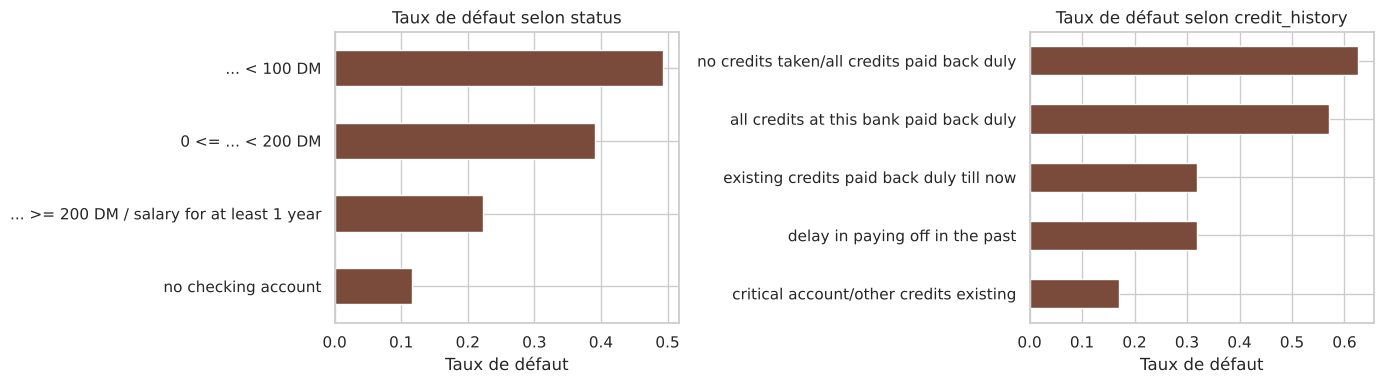

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ["status", "credit_history"]):
    (df.groupby(col)["defaut"].mean().sort_values()
       .plot.barh(ax=ax, color="#7A4B3A"))
    ax.set_title(f"Taux de défaut selon {col}"); ax.set_xlabel("Taux de défaut"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig("figures/taux_defaut_categories.png", dpi=120); plt.show()

Le **solde du compte courant** (`status`) est très discriminant : 12 % de défaut chez les clients sans compte courant, contre 49 % chez ceux dont le solde est le plus faible (< 100 DM).

## 2. Préparation des données

**Choix éthique** : on retire `personal_status_sex` (sexe et situation familiale) et `foreign_worker` (nationalité). Utiliser ces variables pour accorder un crédit serait discriminatoire.

**Étapes**, regroupées dans un `Pipeline` scikit-learn pour éviter toute fuite d'information entre l'entraînement et le test :
- **valeurs extrêmes** : plafonnement (*winsorisation*) des variables numériques au 1er et au 99e percentile, calculés sur le jeu d'entraînement ;
- **standardisation** des variables numériques (moyenne 0, écart-type 1) ;
- **encodage one-hot** des variables catégorielles.

In [7]:
X = df.drop(columns=["defaut", "personal_status_sex", "foreign_worker"])
y = df["defaut"]

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
print("Variables numériques :", num_cols)
print("Variables catégorielles :", cat_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Entraînement : {len(X_train)} clients | Test : {len(X_test)} clients")

Variables numériques : ['duration', 'amount', 'installment_rate', 'present_residence', 'age', 'number_credits', 'people_liable']
Variables catégorielles : ['status', 'credit_history', 'purpose', 'savings', 'employment_duration', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone']
Entraînement : 800 clients | Test : 200 clients


In [8]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Plafonne chaque variable entre deux percentiles appris sur l'entraînement."""
    def __init__(self, low=0.01, high=0.99):
        self.low, self.high = low, high
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.low_ = np.quantile(X, self.low, axis=0)
        self.high_ = np.quantile(X, self.high, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.low_, self.high_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

preprocess = ColumnTransformer([
    ("num", Pipeline([("winsor", Winsorizer()), ("scale", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

X_train_prep = preprocess.fit_transform(X_train)
print("Nombre de variables après encodage :", X_train_prep.shape[1])

Nombre de variables après encodage : 55


## 3. Analyse en composantes principales (PCA)

Après encodage, on passe de 18 à plus de 50 variables. La PCA permet de voir combien de dimensions « utiles » contiennent les données, et de tester si un modèle sur données réduites fait aussi bien.

23 composantes expliquent 90 % de la variance (sur 55 variables).


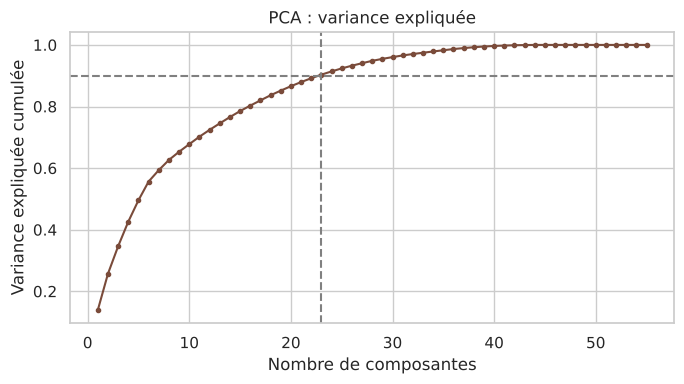

In [9]:
pca = PCA(random_state=SEED).fit(X_train_prep)
var_cum = np.cumsum(pca.explained_variance_ratio_)
n90 = int(np.argmax(var_cum >= 0.90) + 1)
print(f"{n90} composantes expliquent 90 % de la variance (sur {X_train_prep.shape[1]} variables).")

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(var_cum) + 1), var_cum, marker=".", color="#7A4B3A")
plt.axhline(0.90, ls="--", color="grey"); plt.axvline(n90, ls="--", color="grey")
plt.xlabel("Nombre de composantes"); plt.ylabel("Variance expliquée cumulée")
plt.title("PCA : variance expliquée")
plt.tight_layout(); plt.savefig("figures/pca_variance.png", dpi=120); plt.show()

## 4. Comparaison de modèles

On compare quatre modèles en **validation croisée stratifiée à 5 plis** sur le jeu d'entraînement uniquement :
- régression logistique (modèle de référence en scoring, facile à interpréter) ;
- régression logistique après PCA ;
- forêt aléatoire ;
- gradient boosting.

On ne rééquilibre pas les classes à l'entraînement : on garde ainsi des **probabilités de défaut fiables**, et le déséquilibre est traité au moment du **choix du seuil de décision** (section 6). Pour comparer les modèles, on regarde surtout l'**AUC**, qui ne dépend pas du seuil.

In [10]:
models = {
    "Régression logistique": LogisticRegression(max_iter=2000, random_state=SEED),
    "Logistique + PCA": Pipeline([("pca", PCA(n_components=n90, random_state=SEED)),
                                  ("clf", LogisticRegression(max_iter=2000, random_state=SEED))]),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=500, min_samples_leaf=5,
                                              random_state=SEED, n_jobs=-1),
    "Gradient boosting": GradientBoostingClassifier(random_state=SEED),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ["roc_auc", "accuracy", "precision", "recall", "f1"]

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"Modèle": name, **{m: res[f"test_{m}"].mean() for m in scoring},
                 "AUC (écart-type)": res["test_roc_auc"].std()})

resultats_cv = pd.DataFrame(rows).set_index("Modèle").sort_values("roc_auc", ascending=False)
resultats_cv.round(3)

,roc_auc,accuracy,precision,recall,f1,AUC (écart-type)
Modèle,,,,,,
Forêt aléatoire,0.792,0.748,0.673,0.292,0.403,0.040
Gradient boosting,0.775,0.761,0.641,0.458,0.533,0.034
Logistique + PCA,0.774,0.753,0.615,0.454,0.519,0.058
Régression logistique,0.763,0.744,0.598,0.442,0.506,0.057


La **forêt aléatoire** obtient la meilleure AUC moyenne en validation croisée, avec un écart-type parmi les plus faibles. Les écarts entre modèles restent modestes au regard de cet écart-type : avec seulement 800 clients d'entraînement, aucun modèle ne se détache nettement. On retient la forêt aléatoire, qu'on interprétera à la section 7. La PCA change peu les performances de la régression logistique mais fait perdre le lien avec les variables d'origine : elle reste ici un outil d'exploration.

In [11]:
meilleur_nom = resultats_cv["roc_auc"].idxmax()
print("Modèle retenu :", meilleur_nom)

Modèle retenu : Forêt aléatoire


## 5. Évaluation sur le jeu de test (seuil par défaut 0,5)

In [12]:
best = Pipeline([("prep", preprocess), ("model", models[meilleur_nom])])
best.fit(X_train, y_train)
proba_test = best.predict_proba(X_test)[:, 1]

def evaluer(y_true, proba, seuil):
    pred = (proba >= seuil).astype(int)
    return {"Seuil": seuil,
            "Accuracy": accuracy_score(y_true, pred),
            "Précision": precision_score(y_true, pred),
            "Rappel": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred),
            "AUC": roc_auc_score(y_true, proba)}

pd.DataFrame([evaluer(y_test, proba_test, 0.5)]).round(3)

,Seuil,Accuracy,Précision,Rappel,F1,AUC
0,0.5,0.76,0.7,0.35,0.467,0.796


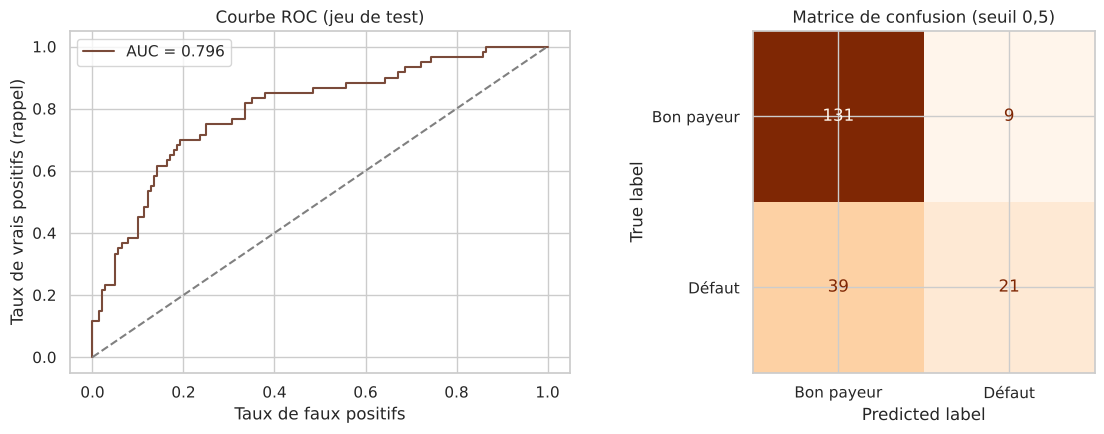

In [13]:
fpr, tpr, _ = roc_curve(y_test, proba_test)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, color="#7A4B3A", label=f"AUC = {roc_auc_score(y_test, proba_test):.3f}")
axes[0].plot([0, 1], [0, 1], ls="--", color="grey")
axes[0].set_xlabel("Taux de faux positifs"); axes[0].set_ylabel("Taux de vrais positifs (rappel)")
axes[0].set_title("Courbe ROC (jeu de test)"); axes[0].legend()
ConfusionMatrixDisplay.from_predictions(y_test, (proba_test >= 0.5).astype(int),
    display_labels=["Bon payeur", "Défaut"], cmap="Oranges", ax=axes[1], colorbar=False)
axes[1].set_title("Matrice de confusion (seuil 0,5)")
plt.tight_layout(); plt.savefig("figures/roc_confusion.png", dpi=120); plt.show()

L'AUC est proche de 0,8, mais avec le seuil par défaut de 0,5 le modèle ne détecte qu'**un défaut sur trois** (rappel faible) : il est trop « optimiste ». C'est ce que corrige la section suivante.

## 6. Choix du seuil de décision

Le seuil de 0,5 n'a rien d'optimal. En crédit, les deux erreurs n'ont pas le même coût :
- **accorder un crédit à un client qui fera défaut** (faux négatif) fait perdre une partie du capital ;
- **refuser un bon client** (faux positif) fait seulement perdre la marge d'intérêt.

On reprend la matrice de coûts fournie avec ce jeu de données : un faux négatif coûte **5**, un faux positif coûte **1**.

Pour ne pas « tricher » avec le test, le seuil est choisi sur des **prédictions en validation croisée** du jeu d'entraînement, puis appliqué une seule fois au jeu de test.

Seuil qui minimise le coût (validation croisée) : 0.25


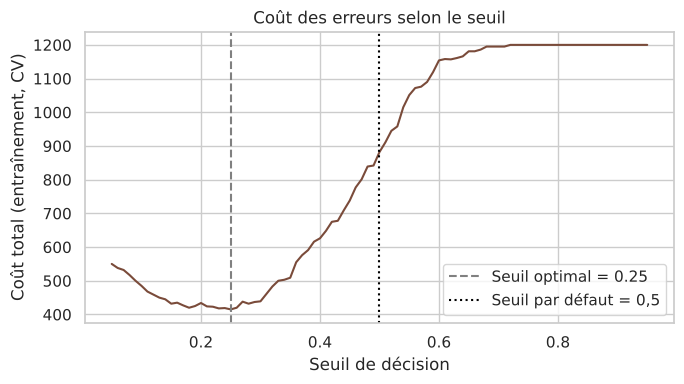

In [14]:
COUT_FN, COUT_FP = 5, 1

proba_cv = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

seuils = np.round(np.arange(0.05, 0.96, 0.01), 2)
def cout_total(y_true, proba, s):
    pred = (proba >= s).astype(int)
    fn = ((pred == 0) & (y_true == 1)).sum()
    fp = ((pred == 1) & (y_true == 0)).sum()
    return COUT_FN * fn + COUT_FP * fp

couts = [cout_total(y_train.values, proba_cv, s) for s in seuils]
seuil_opt = seuils[int(np.argmin(couts))]
print(f"Seuil qui minimise le coût (validation croisée) : {seuil_opt}")

plt.figure(figsize=(7, 4))
plt.plot(seuils, couts, color="#7A4B3A")
plt.axvline(seuil_opt, ls="--", color="grey", label=f"Seuil optimal = {seuil_opt}")
plt.axvline(0.5, ls=":", color="black", label="Seuil par défaut = 0,5")
plt.xlabel("Seuil de décision"); plt.ylabel("Coût total (entraînement, CV)")
plt.title("Coût des erreurs selon le seuil"); plt.legend()
plt.tight_layout(); plt.savefig("figures/cout_seuil.png", dpi=120); plt.show()

In [15]:
comparaison = pd.DataFrame([evaluer(y_test, proba_test, 0.5), evaluer(y_test, proba_test, seuil_opt)])
comparaison["Coût total"] = [cout_total(y_test.values, proba_test, s) for s in [0.5, seuil_opt]]
comparaison.round(3)

,Seuil,Accuracy,Précision,Rappel,F1,AUC,Coût total
0,0.50,0.760,0.700,0.35,0.467,0.796,204
1,0.25,0.635,0.443,0.85,0.583,0.796,109


Avec le seuil optimisé, le modèle **détecte beaucoup plus de défauts** (rappel plus élevé), au prix de davantage de bons clients refusés. Comme un défaut coûte cinq fois plus cher, le **coût total baisse**. L'accuracy diminue : c'est normal, et c'est pour cela qu'elle n'est pas le bon critère ici.

## 7. Interprétation du modèle

Une forêt aléatoire n'a pas de coefficients. On mesure l'**importance par permutation** : on mélange au hasard une variable dans le jeu de test et on regarde de combien l'AUC baisse. Plus la baisse est forte, plus le modèle s'appuie sur cette variable.

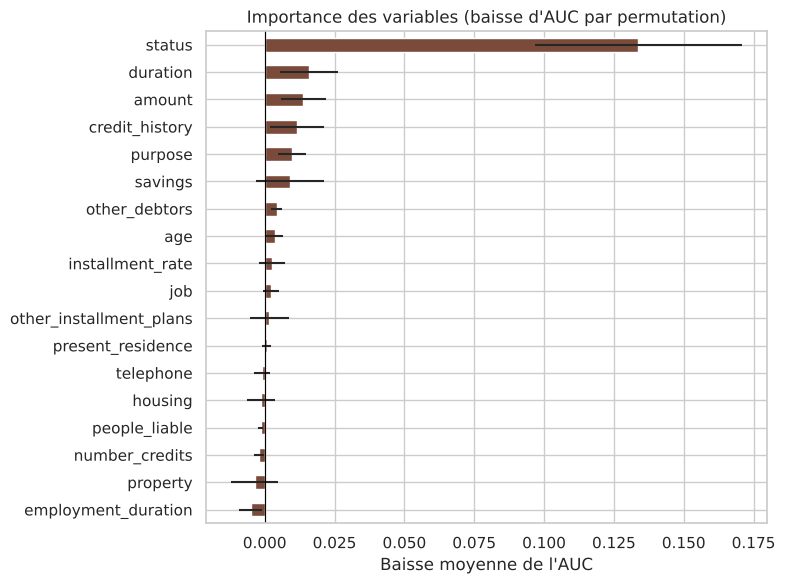

status            0.134
duration          0.016
amount            0.014
credit_history    0.012
purpose           0.010
dtype: float64

In [16]:
imp = permutation_importance(best, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEED, n_jobs=-1)
importances = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
ecarts = pd.Series(imp.importances_std, index=X_test.columns)[importances.index]

plt.figure(figsize=(8, 6))
importances.plot.barh(color="#7A4B3A", xerr=ecarts)
plt.axvline(0, color="black", lw=0.8)
plt.title("Importance des variables (baisse d'AUC par permutation)")
plt.xlabel("Baisse moyenne de l'AUC")
plt.tight_layout(); plt.savefig("figures/importance_variables.png", dpi=120); plt.show()
importances.sort_values(ascending=False).head(5).round(3)

Le **solde du compte courant** est de loin la variable la plus importante, suivie de la **durée**, du **montant**, de l'**historique de crédit** et de l'**objet du crédit**. C'est cohérent avec l'exploration de la section 1 et avec la pratique bancaire.

## 8. Conclusion et limites

**Résultats**
- Modèle retenu : **forêt aléatoire**, avec une **AUC d'environ 0,8** sur le jeu de test.
- Le **choix du seuil selon le coût des erreurs** (0,25 au lieu de 0,5) fait passer la détection des défauts d'environ 35 % à 85 % et réduit le coût total d'environ 45 % sur le jeu de test.
- Les variables sensibles (sexe, nationalité) ont été **exclues** du modèle.

**Limites**
- Petit jeu de données (1 000 clients) et ancien : les résultats ne sont pas transposables tels quels à une banque actuelle.
- La matrice de coûts 5/1 est une convention ; dans un cas réel, elle serait fixée avec le métier.
- Retirer les variables sensibles ne garantit pas l'absence de biais (d'autres variables peuvent leur être corrélées) : une analyse d'équité serait la prochaine étape.

**Pistes**
- Analyse d'équité (taux de refus par groupe d'âge, par exemple).
- Optimisation des hyperparamètres et comparaison avec un modèle plus simple et plus transparent (régression logistique), souvent exigé en banque.
- Calibration des probabilités et explication individuelle des décisions (SHAP).